# EEG Step 3C — Scientific Evaluation of Extreme Absolute Power

**Purpose:** evaluate how strongly extreme absolute ROI power values affect descriptive summaries and PRE–POST changes. This notebook does **not** automatically exclude observations and does not make artifact diagnoses.

Analyses: (1) distribution summaries on raw absolute power, (2) natural-log transform of positive power values, (3) sensitivity comparison with robust outlier flags excluded, (4) paired PRE–POST change summaries, and (5) exported audit tables/plots.

The outlier sensitivity flags are recomputed within task × group × session × condition × band × ROI strata using IQR and MAD. They are exploratory flags, not clinical/artifact labels and not a replacement for Step 3A flags.

In [26]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt

# Edit this only if your project folders are elsewhere.
PROJECT_DIR = Path.cwd()
OUTPUT_DIR = PROJECT_DIR / 'eeg_step3C_absolute_power_evaluation_outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
print('Working directory:', PROJECT_DIR.resolve())
print('Output folder:', OUTPUT_DIR.resolve())

Working directory: /Users/ananyosen/Documents/Term Project/analysis
Output folder: /Users/ananyosen/Documents/Term Project/analysis/eeg_step3C_absolute_power_evaluation_outputs


## 1. Locate and load the ROI power dataset

Set the input file below if automatic search finds the wrong file. We expect the ROI-level long file created in Step 2.

In [27]:
# Search current folder and nearby subfolders for the Step 2 ROI-long file.
SEARCH_ROOT = PROJECT_DIR
found = list(SEARCH_ROOT.rglob('eeg_roi_power_long.csv'))
print('Candidates:')
for p in found[:20]: print(p)

# If needed, manually set INPUT_FILE to a full path string.
INPUT_FILE = None  # e.g. r'/path/to/eeg_roi_power_long.csv'
if INPUT_FILE is None:
    if len(found) != 1:
        raise FileNotFoundError(f'Expected exactly one eeg_roi_power_long.csv; found {len(found)}. Set INPUT_FILE manually.')
    INPUT_FILE = found[0]
else:
    INPUT_FILE = Path(INPUT_FILE)

df = pd.read_csv(INPUT_FILE)
print('Loaded:', INPUT_FILE)
print('Shape:', df.shape)
print('Columns:', df.columns.tolist())
display(df.head())

Candidates:
/Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/eeg_roi_power_long.csv
Loaded: /Users/ananyosen/Documents/Term Project/analysis/eeg_roi_step2_outputs/eeg_roi_power_long.csv
Shape: (8000, 12)
Columns: ['subject_id', 'session', 'run', 'condition', 'band', 'roi', 'absolute_power_roi', 'relative_power_roi', 'channels_in_roi', 'channel_rows_in_roi', 'task', 'group']


,subject_id,session,run,condition,band,roi,absolute_power_roi,relative_power_roi,channels_in_roi,channel_rows_in_roi,task,group
0,Mc02,POST,1,Baseline,alpha,Central,1.949249e+05,2.974069,7,7,Math,Control
1,Mc02,POST,1,Baseline,alpha,Frontal,2.059453e+05,2.826049,7,7,Math,Control
2,Mc02,POST,1,Baseline,alpha,Occipital,2.646393e+06,2.780578,3,3,Math,Control
3,Mc02,POST,1,Baseline,alpha,Parietal,1.215410e+06,2.811652,9,9,Math,Control
4,Mc02,POST,1,Baseline,alpha,Temporal,8.045918e+05,2.551062,6,6,Math,Control


## 2. Configure column names

The notebook attempts common column-name variants. If any field is not detected, edit the mapping manually after reviewing the printed columns. The task/group/session/condition/band/ROI fields are needed for stratified summaries and pairing.

In [28]:
def find_col(candidates, required=True):
    normalized = {str(c).lower().strip().replace(' ', '_'): c for c in df.columns}
    for cand in candidates:
        key = cand.lower().strip().replace(' ', '_')
        if key in normalized: return normalized[key]
    if required: raise KeyError(f'Could not detect any of {candidates}. Available: {df.columns.tolist()}')
    return None

COL = {
 'participant': find_col(['participant','participant_id','subject','subject_id','sub']),
 'group': find_col(['group','cohort']),
 'task': find_col(['task','paradigm']),
 'session': find_col(['session','ses','timepoint']),
 'condition': find_col(['condition','activity','block','condition_name']),
 'band': find_col(['band','frequency_band','freq_band']),
 'roi': find_col(['roi','region','region_of_interest']),
 'absolute': find_col(['absolute_power_roi','absolute_power','abs_power','power_absolute','absolute','power'], required=False),
}
print(COL)
if COL['absolute'] is None:
    raise KeyError("Absolute-power column not detected. Set COL[\'absolute\'] to the exact column name from the dataset.")

{'participant': 'subject_id', 'group': 'group', 'task': 'task', 'session': 'session', 'condition': 'condition', 'band': 'band', 'roi': 'roi', 'absolute': 'absolute_power_roi'}


## 3. Clean/standardize the working fields

Keep original data intact; make a separate working dataframe. Nonpositive absolute power cannot be log-transformed and is counted explicitly.

In [29]:
d = df.copy()
for k, c in COL.items():
    if c is not None: d[k] = d[c]
d['absolute'] = pd.to_numeric(d['absolute'], errors='coerce')
d['log_absolute'] = np.where(d['absolute'] > 0, np.log(d['absolute']), np.nan)

print('Rows:', len(d))
print('Missing/non-numeric absolute power:', d['absolute'].isna().sum())
print('Nonpositive values (not log-transformable):', (d['absolute'] <= 0).sum())
print('Participants:', d['participant'].nunique())
print('Groups:', d['group'].dropna().unique())
print('Tasks:', d['task'].dropna().unique())
print('Sessions:', d['session'].dropna().unique())

Rows: 8000
Missing/non-numeric absolute power: 0
Nonpositive values (not log-transformable): 0
Participants: 63
Groups: <ArrowStringArray>
['Control', 'Experiment']
Length: 2, dtype: str
Tasks: <ArrowStringArray>
['Math', 'Reading']
Length: 2, dtype: str
Sessions: <ArrowStringArray>
['POST', 'PRE']
Length: 2, dtype: str


## 4. Distribution summaries and visual inspection

Summaries are computed by band and ROI, pooled across study dimensions for an initial global view, then stratified in subsequent tables. The global pooled plots are diagnostic—not inferential.

,band,roi,n,mean,median,sd,min,max,mean_log,median_log
0,alpha,Central,320,3.749776e+05,1.090403e+03,1.570680e+06,0.859533,1.311570e+07,7.349787,6.994130
1,alpha,Frontal,320,4.065147e+05,1.036388e+03,1.740312e+06,0.894782,1.508856e+07,7.338050,6.941740
2,alpha,Occipital,320,1.911458e+07,2.349764e+06,4.481155e+07,0.852056,4.122638e+08,12.307824,14.669784
3,alpha,Parietal,320,7.596302e+06,3.688140e+05,1.902770e+07,1.991060,1.277875e+08,11.513533,12.818047
4,alpha,Temporal,320,7.421868e+06,2.899998e+05,1.642395e+07,1.022739,1.318596e+08,11.008390,12.577033
5,beta,Central,320,4.371936e+05,1.116205e+03,1.758942e+06,2.628420,1.681781e+07,7.698138,7.017685
6,beta,Frontal,320,4.375967e+05,1.210468e+03,1.754824e+06,2.744991,1.747128e+07,7.757217,7.098262
7,beta,Occipital,320,2.262205e+07,3.160398e+06,5.092589e+07,2.472900,4.621716e+08,12.599944,14.965855
8,beta,Parietal,320,8.279908e+06,5.581796e+05,2.051442e+07,4.099383,1.443490e+08,11.736422,13.232420
9,beta,Temporal,320,8.504502e+06,4.291821e+05,1.980454e+07,3.094588,1.962860e+08,11.395206,12.969423


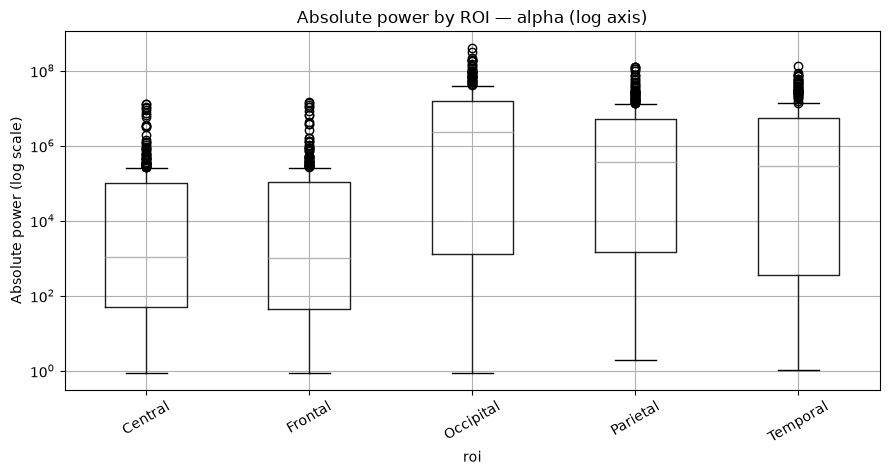

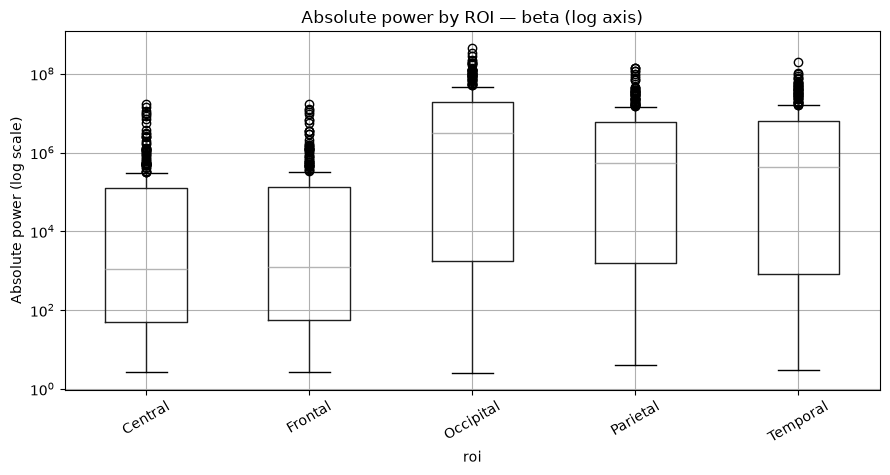

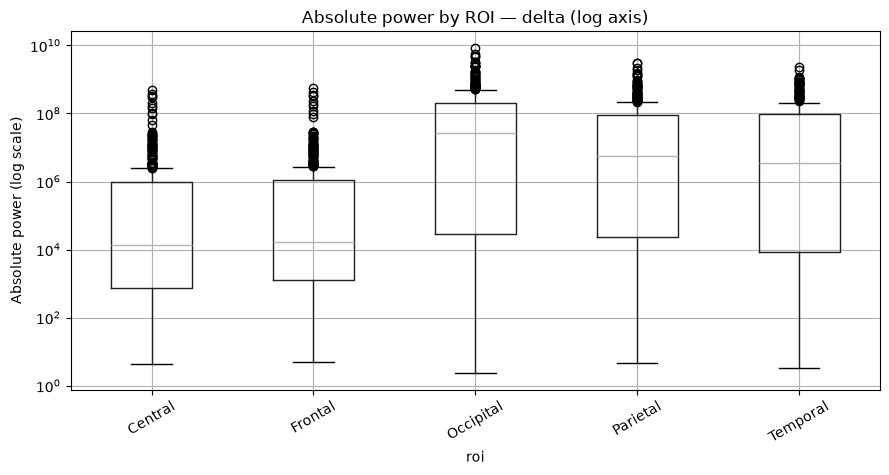

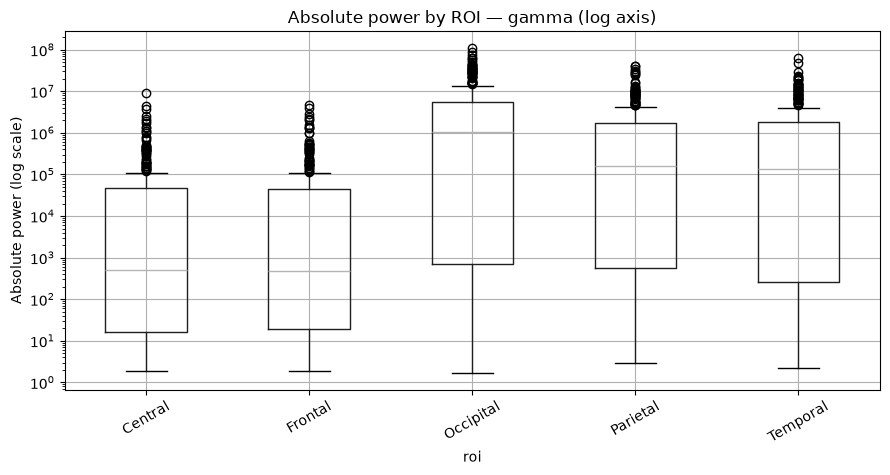

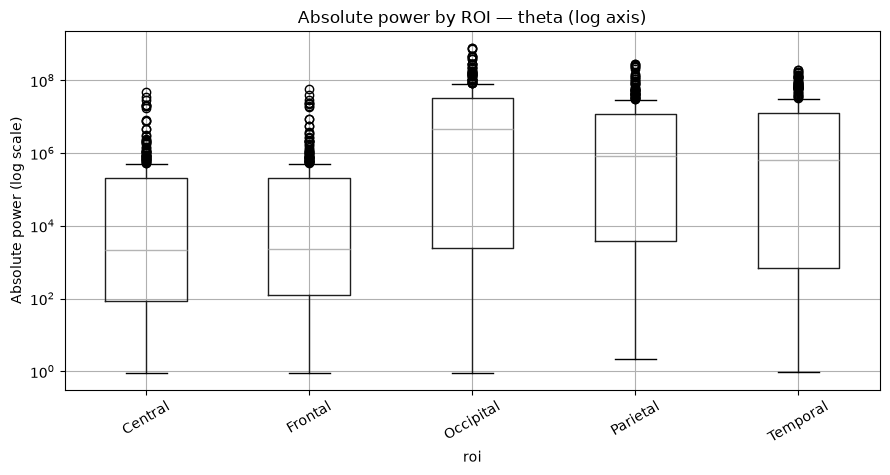

In [30]:
dist_summary = d.groupby(['band','roi'], dropna=False).agg(
    n=('absolute','count'), mean=('absolute','mean'), median=('absolute','median'),
    sd=('absolute','std'), min=('absolute','min'), max=('absolute','max'),
    mean_log=('log_absolute','mean'), median_log=('log_absolute','median')
).reset_index()
dist_summary.to_csv(OUTPUT_DIR/'step3C_distribution_summary_band_roi.csv', index=False)
display(dist_summary.head(20))

# Raw absolute-power boxplots (log y-scale helps visualize extreme spread while retaining original units).
for band in sorted(d['band'].dropna().unique()):
    sub=d[d['band']==band]
    fig, ax = plt.subplots(figsize=(9,5))
    sub.boxplot(column='absolute', by='roi', ax=ax, rot=30)
    ax.set_yscale('log')
    ax.set_title(f'Absolute power by ROI — {band} (log axis)')
    fig.suptitle('')
    ax.set_ylabel('Absolute power (log scale)')
    plt.tight_layout()
    fig.savefig(OUTPUT_DIR/f'boxplot_absolute_{str(band).replace("/","_")}.png', dpi=160)
    plt.show()

## 5. Exploratory outlier flags for sensitivity analysis

Within each task × group × session × condition × band × ROI stratum, flag values outside the Tukey IQR fence and/or robust MAD fence. If a stratum is too small or MAD is zero, that method may not flag any values. These flags are sensitivity markers only.

In [31]:
STRATA = ['task','group','session','condition','band','roi']
def flag_group(g):
    x=g['absolute'].astype(float)
    q1,q3=x.quantile(.25),x.quantile(.75); iqr=q3-q1
    iqr_flag=(x < q1-1.5*iqr) | (x > q3+1.5*iqr) if iqr>0 else pd.Series(False,index=g.index)
    med=x.median(); mad=(x-med).abs().median()
    if mad>0:
        z=0.6745*(x-med)/mad
        mad_flag=z.abs()>3.5
    else: mad_flag=pd.Series(False,index=g.index)
    out=g.copy(); out['iqr_flag']=iqr_flag; out['mad_flag']=mad_flag; out['any_flag']=iqr_flag|mad_flag
    return out

# Avoid groupby.apply(include_groups=...), which is unsupported in older pandas versions.
flagged_parts=[]
for _, group in d.groupby(STRATA, dropna=False, sort=False):
    flagged_parts.append(flag_group(group))
flagged=pd.concat(flagged_parts, axis=0).sort_index() if flagged_parts else d.copy()
flagged.to_csv(OUTPUT_DIR/'step3C_flagged_rows_sensitivity.csv', index=False)
flag_summary=flagged.groupby(STRATA, dropna=False).agg(n=('absolute','count'), iqr_flags=('iqr_flag','sum'), mad_flags=('mad_flag','sum'), any_flags=('any_flag','sum')).reset_index()
flag_summary.to_csv(OUTPUT_DIR/'step3C_flag_summary_by_stratum.csv', index=False)
print('Overall flags:', flagged['any_flag'].sum(), '/', len(flagged), f"({flagged['any_flag'].mean():.1%})")
display(flag_summary.head(25))


Overall flags: 2580 / 8000 (32.2%)


,task,group,session,condition,band,roi,n,iqr_flags,mad_flags,any_flags
0,Math,Control,POST,Activity1,alpha,Central,15,2,5,5
1,Math,Control,POST,Activity1,alpha,Frontal,15,2,5,5
2,Math,Control,POST,Activity1,alpha,Occipital,15,1,5,5
3,Math,Control,POST,Activity1,alpha,Parietal,15,2,6,6
4,Math,Control,POST,Activity1,alpha,Temporal,15,3,7,7
5,Math,Control,POST,Activity1,beta,Central,15,1,5,5
6,Math,Control,POST,Activity1,beta,Frontal,15,1,5,5
7,Math,Control,POST,Activity1,beta,Occipital,15,1,3,3
8,Math,Control,POST,Activity1,beta,Parietal,15,2,5,5
9,Math,Control,POST,Activity1,beta,Temporal,15,3,7,7


## 6. Raw vs log-scale summary impact

For each study stratum, compare raw-power mean/median with log-power mean/median. The log scale reduces the influence of large values but changes interpretation: log-power summaries are not in the original physical units.

In [32]:
GROUP_KEYS=['task','group','session','condition','band','roi']
transform_summary=flagged.groupby(GROUP_KEYS, dropna=False).agg(
    n=('absolute','count'), raw_mean=('absolute','mean'), raw_median=('absolute','median'),
    log_mean=('log_absolute','mean'), log_median=('log_absolute','median'),
    flagged_n=('any_flag','sum')
).reset_index()
transform_summary.to_csv(OUTPUT_DIR/'step3C_raw_vs_log_summary.csv', index=False)
display(transform_summary.head(25))

,task,group,session,condition,band,roi,n,raw_mean,raw_median,log_mean,log_median,flagged_n
0,Math,Control,POST,Activity1,alpha,Central,15,1.121400e+05,2.165009e+03,7.313732,7.680180,5
1,Math,Control,POST,Activity1,alpha,Frontal,15,1.189679e+05,2.469283e+03,7.418226,7.811683,5
2,Math,Control,POST,Activity1,alpha,Occipital,15,1.144344e+07,1.296356e+06,12.399279,14.075068,5
3,Math,Control,POST,Activity1,alpha,Parietal,15,4.463802e+06,3.558994e+04,10.376297,10.479818,6
4,Math,Control,POST,Activity1,alpha,Temporal,15,6.011654e+06,2.948474e+04,10.751284,10.291628,7
5,Math,Control,POST,Activity1,beta,Central,15,1.153542e+05,2.085015e+03,7.442755,7.642531,5
6,Math,Control,POST,Activity1,beta,Frontal,15,1.178121e+05,2.368001e+03,7.557610,7.769801,5
7,Math,Control,POST,Activity1,beta,Occipital,15,1.442129e+07,2.377093e+06,12.818124,14.681389,3
8,Math,Control,POST,Activity1,beta,Parietal,15,5.380936e+06,1.220440e+05,10.615006,11.712137,5
9,Math,Control,POST,Activity1,beta,Temporal,15,5.693607e+06,5.182676e+04,10.934257,10.855662,7


## 7. PRE–POST sensitivity summaries

Pair PRE and POST within participant × task × group × condition × band × ROI. This produces paired changes in raw power and log-power. For flagged-excluded sensitivity, remove flagged observations at the row level before pairing; this may reduce pair counts and must be reported. No hypothesis tests are performed in Step 3C.

In [33]:
# Normalize session labels to identify PRE/POST flexibly.
sess = flagged['session'].astype(str).str.lower().str.strip()
pre_mask=sess.str.contains(r'pre|ses-1|session.?1', regex=True)
post_mask=sess.str.contains(r'post|ses-2|session.?2', regex=True)
print('PRE rows:', pre_mask.sum(), 'POST rows:', post_mask.sum())

PAIR_KEYS=['participant','task','group','condition','band','roi']
def make_change_table(frame, label):
    tmp=frame.loc[pre_mask.loc[frame.index] | post_mask.loc[frame.index]].copy()
    ss=tmp['session'].astype(str).str.lower().str.strip()
    tmp['timepoint']=np.where(ss.str.contains(r'pre|ses-1|session.?1'), 'PRE', 'POST')
    wide=tmp.pivot_table(index=PAIR_KEYS, columns='timepoint', values=['absolute','log_absolute'], aggfunc='mean')
    # Flatten columns and keep only matched pairs.
    wide.columns=[f'{metric}_{tp.lower()}' for metric,tp in wide.columns]
    wide=wide.reset_index()
    for metric in ['absolute','log_absolute']:
        a,b=f'{metric}_pre',f'{metric}_post'
        if a in wide and b in wide: wide[f'{metric}_change_post_minus_pre']=wide[b]-wide[a]
    wide['sensitivity']=label
    return wide

paired_all=make_change_table(flagged, 'all observations')
paired_clean=make_change_table(flagged.loc[~flagged['any_flag']], 'flagged rows removed')
paired_all.to_csv(OUTPUT_DIR/'step3C_prepost_changes_all.csv', index=False)
paired_clean.to_csv(OUTPUT_DIR/'step3C_prepost_changes_flagged_removed.csv', index=False)
print('Paired rows (all):', len(paired_all), 'paired rows (flags removed):', len(paired_clean))
display(paired_all.head())

PRE rows: 4000 POST rows: 4000
Paired rows (all): 4000 paired rows (flags removed): 3582


,participant,task,group,condition,band,roi,absolute_post,absolute_pre,log_absolute_post,log_absolute_pre,absolute_change_post_minus_pre,log_absolute_change_post_minus_pre,sensitivity
0,Mc02,Math,Control,Activity1,alpha,Central,1.902903e+05,1070.127898,12.156306,6.975533,1.892201e+05,5.180772,all observations
1,Mc02,Math,Control,Activity1,alpha,Frontal,1.984043e+05,1236.486154,12.198062,7.120029,1.971678e+05,5.078033,all observations
2,Mc02,Math,Control,Activity1,alpha,Occipital,1.915192e+07,7782.719222,16.767914,8.959661,1.914414e+07,7.808253,all observations
3,Mc02,Math,Control,Activity1,alpha,Parietal,4.675033e+06,2223.894645,15.357747,7.707015,4.672809e+06,7.650731,all observations
4,Mc02,Math,Control,Activity1,alpha,Temporal,2.018579e+06,16685.253387,14.517904,9.722281,2.001894e+06,4.795624,all observations


## 8. Compare paired-change distributions

This comparison is descriptive. We report matched-pair counts and median/mean change for raw and log power, both with all data and after flagged-row removal. Large differences indicate that flagged values may materially influence the change summaries and warrant careful interpretation.

In [34]:
def summarize_changes(wide, label):
    rows=[]
    for metric in ['absolute','log_absolute']:
        col=f'{metric}_change_post_minus_pre'
        if col not in wide: continue
        for keys, g in wide.groupby(['task','group','condition','band','roi'], dropna=False):
            vals=g[col].dropna()
            rows.append(dict(zip(['task','group','condition','band','roi'],keys),
                         metric=metric, sensitivity=label, paired_n=len(vals),
                         mean_change=vals.mean(), median_change=vals.median(), sd_change=vals.std()))
    return pd.DataFrame(rows)

change_compare=pd.concat([summarize_changes(paired_all,'all observations'),
                         summarize_changes(paired_clean,'flagged rows removed')], ignore_index=True)
change_compare.to_csv(OUTPUT_DIR/'step3C_change_sensitivity_comparison.csv', index=False)
display(change_compare.head(30))

,task,group,condition,band,roi,metric,sensitivity,paired_n,mean_change,median_change,sd_change
0,Math,Control,Activity1,alpha,Central,absolute,all observations,15,-8.254695e+05,-2.973222e+04,2.193240e+06
1,Math,Control,Activity1,alpha,Frontal,absolute,all observations,15,-8.746880e+05,-3.465958e+04,2.404720e+06
2,Math,Control,Activity1,alpha,Occipital,absolute,all observations,15,-7.329441e+06,-5.966663e+05,2.952271e+07
3,Math,Control,Activity1,alpha,Parietal,absolute,all observations,15,-4.552866e+06,-3.451429e+05,2.158824e+07
4,Math,Control,Activity1,alpha,Temporal,absolute,all observations,15,-5.149774e+06,-6.384098e+05,1.923678e+07
5,Math,Control,Activity1,beta,Central,absolute,all observations,15,-9.762252e+05,-3.625182e+04,2.621598e+06
6,Math,Control,Activity1,beta,Frontal,absolute,all observations,15,-1.062026e+06,-4.165922e+04,2.940320e+06
7,Math,Control,Activity1,beta,Occipital,absolute,all observations,15,-4.906892e+06,-3.098690e+00,2.983461e+07
8,Math,Control,Activity1,beta,Parietal,absolute,all observations,15,-3.910333e+06,-4.681148e+05,2.193990e+07
9,Math,Control,Activity1,beta,Temporal,absolute,all observations,15,-7.035940e+06,-8.769443e+05,1.956180e+07


## 9. Participant-level influence review

Identify participants contributing the largest raw absolute-power observations and summarize how many flagged records they have. This is a triage table—not a basis for exclusion.

In [35]:
participant_review=flagged.groupby(['participant','task','group'], dropna=False).agg(
    n_records=('absolute','count'), flagged_records=('any_flag','sum'),
    max_absolute_power=('absolute','max'), median_absolute_power=('absolute','median')
).reset_index().sort_values('max_absolute_power', ascending=False)
participant_review.to_csv(OUTPUT_DIR/'step3C_participant_extreme_review.csv', index=False)
display(participant_review.head(30))

,participant,task,group,n_records,flagged_records,max_absolute_power,median_absolute_power
6,Mc09,Math,Control,150,73,8.617234e+09,1.033146e+06
52,Re09,Reading,Experiment,100,30,5.424984e+09,3.390710e+04
24,Me10,Math,Experiment,150,88,4.729225e+09,4.937893e+05
9,Mc12,Math,Control,150,51,4.421564e+09,5.136887e+02
18,Me04,Math,Experiment,150,86,3.308835e+09,1.599018e+06
4,Mc06,Math,Control,150,74,3.137039e+09,8.561046e+05
29,Me15,Math,Experiment,150,63,3.031365e+09,4.824512e+05
42,Rc10,Reading,Control,100,25,2.497631e+09,9.556830e+02
27,Me13,Math,Experiment,150,82,2.435806e+09,1.216915e+06
47,Re03,Reading,Experiment,100,47,2.400990e+09,2.584728e+05


## 10. Export audit and decision checklist

Use the checklist below after reviewing the tables/plots. Do not make an exclusion decision solely from an automated flag. Document any decision and its rationale in the final report.

In [36]:
checklist = pd.DataFrame({
 'decision_item':[
  'Are extreme values concentrated in specific participants or channels?',
  'Do flagged observations occur disproportionately in one group/session/task/condition/band/ROI?',
  'Are raw-power PRE–POST changes materially different from log-power changes?',
  'Does removing flagged rows materially alter the direction or magnitude of descriptive change?',
  'Are any flagged observations supported by independent EEG quality evidence (e.g., bad channel/artifact annotations)?',
  'Are there enough matched pairs after sensitivity removal for planned analyses?',
  'Chosen primary metric and transform (to be decided after evidence review)',
  'Exclusion policy (to be decided; no automatic exclusions)'
 ], 'decision_or_notes':['','','','','','','','']})
checklist.to_csv(OUTPUT_DIR/'step3C_researcher_decision_checklist.csv', index=False)
print('Saved outputs to:', OUTPUT_DIR.resolve())
print('Files:')
for p in sorted(OUTPUT_DIR.iterdir()): print(p.name)

Saved outputs to: /Users/ananyosen/Documents/Term Project/analysis/eeg_step3C_absolute_power_evaluation_outputs
Files:
boxplot_absolute_alpha.png
boxplot_absolute_beta.png
boxplot_absolute_delta.png
boxplot_absolute_gamma.png
boxplot_absolute_theta.png
step3C_change_sensitivity_comparison.csv
step3C_distribution_summary_band_roi.csv
step3C_flag_summary_by_stratum.csv
step3C_flagged_rows_sensitivity.csv
step3C_participant_extreme_review.csv
step3C_prepost_changes_all.csv
step3C_prepost_changes_flagged_removed.csv
step3C_raw_vs_log_summary.csv
step3C_researcher_decision_checklist.csv


## Step 3C conclusion template

Complete after reviewing the generated results:
- **Distribution:** Describe raw absolute-power skew and extreme-value concentration.
- **Transformation:** State whether log-power summaries are more stable and how interpretation changes.
- **Sensitivity:** Describe whether flagged-row removal changes paired PRE–POST summaries, including changes in direction, magnitude, and pair count.
- **Quality evidence:** Distinguish statistical extremeness from documented artifact/electrode-quality evidence.
- **Decision:** Record primary metric/transform and whether any exclusion is justified.
- **Limitations:** A log transform does not correct artifacts; an outlier flag does not prove an artifact.

**Important:** inferential testing and multiple-comparison correction are deliberately deferred until this evaluation and the primary analysis plan are locked.